# Measuring data

Input: `data/intermediate/jobs.csv`. Types, results and findings: README, section Preprocessing.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("../data/intermediate/jobs.csv")
pd.set_option("display.float_format", "{:,.2f}".format)  # no scientific notation
FIGURES = Path("../docs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
print(df.shape)

(31901, 31)


In [2]:
NOMINAL = ["title", "role_family", "cities", "states", "industry", "company", "salary_currency", "salary_period"]
BINARY = ["seniority_source", "salary_period_source"]
ORDINAL = {
    "seniority": ["intern", "entry", "mid", "senior", "staff", "lead", "director"],
    "degree": ["bachelor", "master", "phd"],
    "work_mode": ["remote", "hybrid", "onsite"],
    "employment_type": ["contract", "part-time", "full-time"],
}
NUMERIC = ["years_min", "years_max", "office_days", "n_locations", "description_chars"]
MULTI = ["states", "cities", "skills"]  # several values per cell, separated by " | "

## Missing values

In [3]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0]

detail_error           100.00
office_days             95.70
work_mode               45.40
seniority_source        42.40
seniority               42.40
employment_type         36.30
skills                  35.00
degree                  33.10
years_max               29.80
years_min               29.80
salary_max              17.50
states                  15.90
cities                  15.70
salary_currency         15.30
salary_period           15.30
salary_text             15.30
salary_period_source    15.30
salary_min              15.30
posted_date              1.40
dtype: float64

## Nominal: frequency, mode

In [4]:
def frequencies(col):
    values = df[col]
    if col in MULTI:
        values = values.str.split(" | ", regex=False).explode()
    counts = values.value_counts(dropna=False)
    return pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)})


def mode_table(columns):
    rows = []
    for col in columns:
        f = frequencies(col)
        known = f[f.index.notna()]  # mode of the known values; missing is shown separately
        rows.append({
            "column": col,
            "mode": known.index[0],
            "mode_count": known["count"].iloc[0],
            "mode_%": known["percent"].iloc[0],
            "distinct": len(known),
            "missing_%": round(df[col].isna().mean() * 100, 1),
        })
    return pd.DataFrame(rows)


mode_table(NOMINAL)

,column,mode,mode_count,mode_%,distinct,missing_%
0,title,Area Manager II,231,0.70,23318,0.00
1,role_family,other,6043,18.90,18,0.00
2,cities,"Seattle, WA",5229,16.40,1368,15.70
3,states,CA,9274,29.10,51,15.90
4,industry,software_internet,20920,65.60,10,0.00
5,company,amazon,12473,39.10,45,0.00
6,salary_currency,USD,26983,84.60,3,15.30
7,salary_period,year,25827,81.00,3,15.30


In [5]:
for col in NOMINAL:
    print(col)
    display(frequencies(col).head(10))

title


,count,percent
title,,
Area Manager II,231,0.70
Engineering Operation Technician,205,0.60
Operations Manager,166,0.50
Data Center Technician,145,0.50
Area Manager,106,0.30
Sr. Operations Manager,105,0.30
EHS Specialist,96,0.30
Installation Technician,92,0.30
Engineering Operations Technician,79,0.20


role_family


,count,percent
role_family,,
other,6043,18.90
engineering,5392,16.90
software,3561,11.20
data,3290,10.30
hardware,1849,5.80
sales,1508,4.70
devops,1462,4.60
program,1411,4.40
operations,1406,4.40


cities


,count,percent
cities,,
"Seattle, WA",5229,16.40
NaN,4996,15.70
"New York, NY",4172,13.10
"San Francisco, CA",3414,10.70
"Austin, TX",3046,9.50
"Nashville, TN",2144,6.70
"Arlington, VA",2139,6.70
"Redmond, WA",1996,6.30
"Santa Clara, CA",1943,6.10


... (6 outputs left out)

salary_currency


,count,percent
salary_currency,,
USD,26983,84.60
NaN,4881,15.30
EUR,20,0.10
CAD,17,0.10


salary_period


,count,percent
salary_period,,
year,25827,81.00
NaN,4881,15.30
hour,1156,3.60
month,37,0.10


## Binary: frequency, mode

In [6]:
mode_table(BINARY)

,column,mode,mode_count,mode_%,distinct,missing_%
0,seniority_source,title,18197,57.00,2,42.40
1,salary_period_source,stated,17875,56.00,2,15.30


In [7]:
for col in BINARY:
    print(col)
    display(frequencies(col))

seniority_source


,count,percent
seniority_source,,
title,18197,57.00
NaN,13528,42.40
platform,176,0.60


salary_period_source


,count,percent
salary_period_source,,
stated,17875,56.00
inferred,9145,28.70
NaN,4881,15.30


In [8]:
skills = frequencies("skills")
print("distinct skills:", skills.index.notna().sum())
skills.head(20)

distinct skills: 43


,count,percent
skills,,
NaN,11167,35.00
AWS,7280,22.80
Python,7046,22.10
Machine Learning,5906,18.50
LLM,4483,14.10
C++,4396,13.80
Java,3314,10.40
SQL,2790,8.70
Linux,2391,7.50


## Ordinal: frequency, mode, median, quartiles

In [9]:
def ordered(col):
    order = ORDINAL[col]
    assert df[col].dropna().isin(order).all(), f"{col} has a value missing from its order"
    return pd.Series(pd.Categorical(df[col], categories=order, ordered=True))


for col in ORDINAL:
    counts = ordered(col).value_counts(dropna=False, sort=False)
    print(col)
    display(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)}))

seniority


,count,percent
intern,723,2.30
entry,270,0.80
mid,1037,3.30
senior,6414,20.10
staff,2833,8.90
lead,6120,19.20
director,976,3.10
NaN,13528,42.40


degree


,count,percent
bachelor,19015,59.60
master,1402,4.40
phd,924,2.90
NaN,10560,33.10


work_mode


,count,percent
remote,1725,5.40
hybrid,2721,8.50
onsite,12960,40.60
NaN,14495,45.40


employment_type


,count,percent
contract,34,0.10
part-time,117,0.40
full-time,20163,63.20
NaN,11587,36.30


In [10]:
rows = []
for col, order in ORDINAL.items():
    codes = pd.Series(ordered(col).cat.codes)
    codes = codes[codes >= 0]  # -1 is a missing value
    position = lambda p: order[int(codes.quantile(p, interpolation="lower"))]
    rows.append({
        "column": col,
        "min": order[codes.min()],
        "Q1": position(0.25),
        "median": position(0.5),
        "Q3": position(0.75),
        "max": order[codes.max()],
        "mode": order[codes.mode()[0]],
        "missing_%": round(df[col].isna().mean() * 100, 1),
    })
pd.DataFrame(rows)

,column,min,Q1,median,Q3,max,mode,missing_%
0,seniority,intern,senior,staff,lead,director,senior,42.40
1,degree,bachelor,bachelor,bachelor,bachelor,phd,bachelor,33.10
2,work_mode,remote,hybrid,onsite,onsite,onsite,onsite,45.40
3,employment_type,contract,full-time,full-time,full-time,full-time,full-time,36.30


## Numeric: all measures

In [11]:
def numeric_summary(s):
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return {
        "count": len(s),
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode()[0],
        "min": s.min(),
        "Q1": q1,
        "Q3": q3,
        "max": s.max(),
        "midrange": (s.min() + s.max()) / 2,
        "range": s.max() - s.min(),
        "IQR": iqr,
        "P5": s.quantile(0.05),
        "P95": s.quantile(0.95),
        "variance": s.var(),
        "std": s.std(),
        "skewness": s.skew(),
        "kurtosis": s.kurt(),
        "outliers (1.5 IQR)": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum(),
    }


pd.DataFrame({col: numeric_summary(df[col]) for col in NUMERIC}).round(2)

,years_min,years_max,office_days,n_locations,description_chars
count,"22,410.00","22,410.00","1,367.00","31,901.00","31,901.00"
mean,4.73,6.04,2.62,2.50,"6,210.13"
median,4.00,5.00,3.00,1.00,"5,929.00"
mode,5.00,5.00,3.00,1.00,"5,834.00"
min,0.00,0.00,0.00,0.00,74.00
Q1,2.00,3.00,3.00,1.00,"4,666.00"
Q3,7.00,8.00,3.00,2.00,"7,457.00"
max,20.00,20.00,5.00,121.00,"55,750.00"
midrange,10.00,10.00,2.50,60.50,"27,912.00"
range,20.00,20.00,5.00,121.00,"55,676.00"


## Salary, per pay period

In [12]:
usd = df[df["salary_currency"] == "USD"]
salary = {"salary_min (all rows)": numeric_summary(df["salary_min"])}
for period, group in usd.groupby("salary_period"):
    salary[f"salary_min ({period})"] = numeric_summary(group["salary_min"])
    salary[f"salary_max ({period})"] = numeric_summary(group["salary_max"])
pd.DataFrame(salary).round(1)

,salary_min (all rows),salary_min (hour),salary_max (hour),salary_min (month),salary_max (month),salary_min (year),salary_max (year)
count,"27,020.00","1,156.00",969.00,35.00,35.00,"25,792.00","25,273.00"
mean,"142,467.60",31.60,52.60,"6,554.00","12,961.10","149,121.90","230,234.00"
median,"142,300.00",28.10,50.70,"6,810.00","13,480.00","143,700.00","215,250.00"
mode,"143,700.00",20.00,63.60,"6,810.00","13,480.00","143,700.00","194,400.00"
min,5.00,5.00,20.00,"5,690.00","11,210.00","8,625.00","49,920.00"
Q1,"102,300.00",22.80,35.00,"6,810.00","13,480.00","111,300.00","182,400.00"
Q3,"174,000.00",38.00,63.60,"6,810.00","13,480.00","175,000.00","269,080.00"
max,"890,000.00",196.70,255.60,"6,810.00","13,480.00","890,000.00","1,690,000.00"
midrange,"445,002.50",100.90,137.80,"6,250.00","12,345.00","449,312.50","869,960.00"
range,"889,995.00",191.70,235.60,"1,120.00","2,270.00","881,375.00","1,640,080.00"


In [13]:
pd.crosstab(df["salary_period"], df["salary_currency"], dropna=False)

salary_currency,CAD,EUR,USD,NaN
salary_period,,,,
hour,0,0,1156,0
month,2,0,35,0
year,15,20,25792,0
NaN,0,0,0,4881


## Posted date (interval)

In [14]:
posted = pd.to_datetime(df["posted_date"])
days = (posted - posted.min()).dt.days

display(posted.describe())  # count, mean, min, Q1, median, Q3, max
print("mode:      ", posted.mode()[0].date())
print("midrange:  ", (posted.min() + (posted.max() - posted.min()) / 2).date())
print("range:     ", posted.max() - posted.min())
print("IQR:       ", posted.quantile(0.75) - posted.quantile(0.25))
print("std (days):", round(days.std(), 1))
print("skewness:  ", round(days.skew(), 2))
print("kurtosis:  ", round(days.kurt(), 2))

count                         31464
mean     2026-08-24 22:28:36.247139
min             2017-11-30 00:00:00
25%             2026-08-14 00:00:00
50%             2026-09-30 00:00:00
75%             2026-10-23 00:00:00
max             2026-11-05 00:00:00
Name: posted_date, dtype: object

mode:       2026-10-30


midrange:   2022-05-19
range:      3262 days 00:00:00
IQR:        70 days 00:00:00
std (days): 138.1
skewness:   -7.59
kurtosis:   86.25


## Duplicates and repeated columns

In [15]:
SAME_JOB = ["company", "title", "salary_min", "salary_max", "description_chars"]
print("exact duplicate rows:  ", df.duplicated().sum())
print("repeated job_id:       ", df["job_id"].duplicated().sum())
print("same job, another id:  ", df.duplicated(SAME_JOB).sum() - df.duplicated().sum())
print("names per company:     ", df.groupby("company")["company_name"].nunique().max())
print("distinct collected_date:", df["collected_date"].nunique())

exact duplicate rows:   157
repeated job_id:        157


same job, another id:   2597
names per company:      1
distinct collected_date: 1


## Plots (saved in docs/figures)

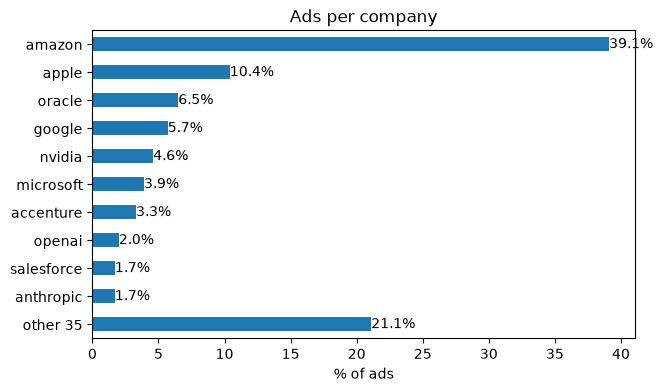

In [16]:
top = frequencies("company").head(10)["percent"]
top["other 35"] = round(100 - top.sum(), 1)

fig, ax = plt.subplots(figsize=(7, 4))
top[::-1].plot.barh(ax=ax, color="tab:blue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_xlabel("% of ads")
ax.set_ylabel("")
ax.set_title("Ads per company")
plt.savefig(FIGURES / "company.png", dpi=200, bbox_inches="tight")
plt.show()

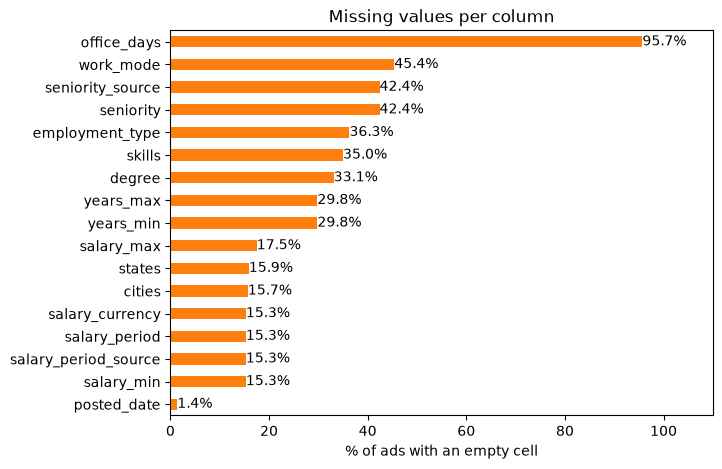

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
missing[missing > 0].drop(["detail_error", "salary_text"])[::-1].plot.barh(ax=ax, color="tab:orange")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_xlabel("% of ads with an empty cell")
ax.set_xlim(0, 110)  # room for the 95.7% label
ax.set_title("Missing values per column")
plt.savefig(FIGURES / "missing.png", dpi=200, bbox_inches="tight")
plt.show()

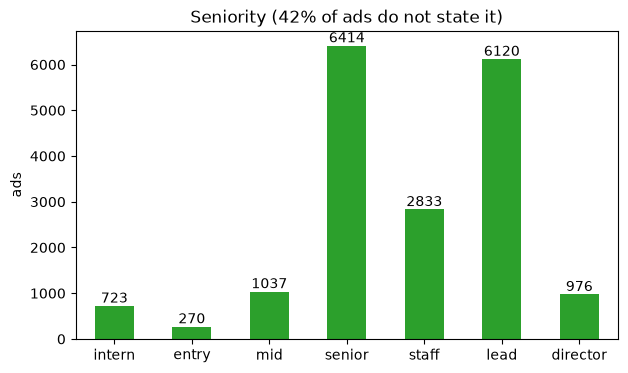

In [18]:
counts = ordered("seniority").value_counts(sort=False)
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot.bar(ax=ax, color="tab:green", rot=0)
ax.bar_label(ax.containers[0])
ax.set_ylabel("ads")
ax.set_title(f"Seniority ({df['seniority'].isna().mean():.0%} of ads do not state it)")
plt.savefig(FIGURES / "seniority.png", dpi=200, bbox_inches="tight")
plt.show()

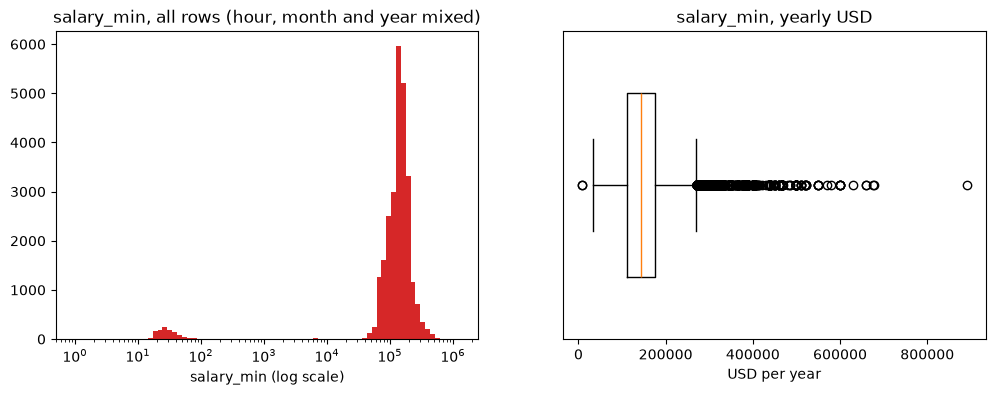

In [19]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))

bins = np.logspace(0, 6.1, 80)  # log scale: an hourly 50 and a yearly 150,000 on one axis
left.hist(df["salary_min"].dropna(), bins=bins, color="tab:red")
left.set_xscale("log")
left.set_title("salary_min, all rows (hour, month and year mixed)")
left.set_xlabel("salary_min (log scale)")

yearly = usd.loc[usd["salary_period"] == "year", "salary_min"].dropna()
right.boxplot(yearly, orientation="horizontal", widths=0.6)
right.set_title("salary_min, yearly USD")
right.set_xlabel("USD per year")
right.set_yticks([])

plt.savefig(FIGURES / "salary.png", dpi=200, bbox_inches="tight")
plt.show()